# 8. Spot-to-fiber tracing with jie on seqFISH+ data

:func:`uchrom.im.trace.align_spots` is an independent reimplementation
of jie (Jia & Ren 2022, *Nature Biotechnology* 22,
doi:10.1038/s41587-022-01568-9), a *spatial genome aligner* that
resolves spot-to-fiber assignment in multiplexed DNA-FISH data.

Where do the tutorials so far start?  The FOF-CT files we've been
using (4DN `4DNFIHF3JCBY`) already carry a ``trace_id`` column — the
fiber each spot belongs to has been assigned upstream.  But before
that assignment, the raw seqFISH+ output looks like this:

- Every cell has **multiple candidate spots per locus** (noise, sister
  chromatids, copy-number variants → often 3–8 per 25-kb region).
- No ground-truth link tells you which spot lies on which chromatin
  fiber.

jie decides:

1. For each (cell, chromosome), build a DAG over candidate spots
   ordered by genomic position.
2. Score each candidate edge by the Gaussian-chain bond probability —
   "how plausibly are these two spots linked by a ~L-bp piece of
   chromatin?"
3. Shortest path picks one spot per locus; iterate (masking used
   spots) to extract all fibers → **ploidy emerges naturally**.
4. Post-hoc sister-chromatid detection groups fibers whose
   co-locus distances stay within a threshold.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from uchrom.im.trace import align_spots, SpotAlignerParams
from uchrom import ChromData


## Auto-download the Takei 2021 seqFISH+ spot-level data

The raw detections used by Jia & Ren 2022 live in Takei et al. 2021's
Zenodo deposit (doi:10.5281/zenodo.3735329, 144 MB zip — slower than
the FOF-CT file used in previous tutorials, so cache aggressively).

The archive contains eight CSVs; we use
``DNAseqFISH+25kbloci-E14-replicate1.csv`` (~35 MB uncompressed) which
has 46 mESC cells × 20 chromosomes × 60 loci at 25-kb resolution.


In [2]:
import zipfile
import urllib.request

DATA_URL = (
    'https://zenodo.org/records/3735329/files/DNAseqFISH%2B.zip?download=1'
)

def _repo_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'pyproject.toml').exists():
            return p
    return Path.cwd()

def load_seqfish_spots(variant: str = '25kbloci-E14-replicate1') -> pd.DataFrame:
    '''Download (once) and read one replicate from the Zenodo zip.'''
    root = _repo_root()
    zip_path = root / 'example-data' / 'DNAseqFISH+.zip'
    if not zip_path.exists():
        zip_path.parent.mkdir(parents=True, exist_ok=True)
        print(f'[data] downloading seqFISH+ (~144 MB) → {zip_path}')
        tmp = zip_path.with_suffix('.zip.part')
        urllib.request.urlretrieve(DATA_URL, tmp)
        tmp.rename(zip_path)
    inner = f'DNAseqFISH+/DNAseqFISH+{variant}.csv'
    with zipfile.ZipFile(zip_path) as zf:
        with zf.open(inner) as f:
            return pd.read_csv(f)

raw = load_seqfish_spots()
print('raw shape:', raw.shape)
print('cells:', raw['cellID'].nunique(), ' chromIDs:', raw['chromID'].nunique())
print('spots per (cell, chromID, region):',
      raw.groupby(['cellID', 'chromID', 'regionID (hyb1-60)']).size().describe().round(1).to_dict())


raw shape: (316995, 30)
cells: 46  chromIDs: 20
spots per (cell, chromID, region): {'count': 54835.0, 'mean': 5.8, 'std': 2.5, 'min': 1.0, '25%': 4.0, '50%': 6.0, '75%': 7.0, 'max': 17.0}


The key observation is in the spots-per-(cell, chromID, region) histogram:
**the median is 6 candidate spots per locus** — raw seqFISH+ is very
far from one-spot-per-locus, which is exactly the ambiguity jie is
designed to resolve.


## Convert to the `align_spots` input contract

``align_spots`` expects a long-format DataFrame with columns
``cell_id, chrom, start, end, x, y, z`` (and optional
``sigma_x/y/z, spot_id``).  We translate the seqFISH+ columns:

- ``cellID`` → ``cell_id``
- ``chromID`` → ``chrom`` (1..19 → ``chr1..chr19``, 20 → ``chrX``)
- ``regionID (hyb1-60)`` → bin index along the chromosome, converted
  to ``(start, end)`` at 25-kb resolution.
- ``x, y`` are pixel indices — multiply by 103 nm/pixel.
- ``z`` is pixel index — multiply by 250 nm/pixel.
- We drop ``labelID == -1`` spots (the upstream pipeline's rejected
  detections) and ignore other labelID values so jie works purely from
  geometry.  The ``labelID`` column is kept separately as a
  pre-assigned label we can compare against later.


In [3]:
XY_PIX_NM = 103.0
Z_PIX_NM = 250.0
BIN_SIZE_BP = 25_000

def _chrom_name(cid: int) -> str:
    return 'chrX' if cid == 20 else f'chr{cid}'

raw_good = raw[raw['labelID'] >= 0].copy()
spots_df = pd.DataFrame({
    'spot_id':  np.arange(len(raw_good)),
    'cell_id':  raw_good['cellID'].astype(str).values,
    'chrom':    raw_good['chromID'].map(_chrom_name).values,
    'start':    ((raw_good['regionID (hyb1-60)'] - 1) * BIN_SIZE_BP).astype(int).values,
    'end':      (raw_good['regionID (hyb1-60)'] * BIN_SIZE_BP).astype(int).values,
    'x':        (raw_good['x'] * XY_PIX_NM).values,
    'y':        (raw_good['y'] * XY_PIX_NM).values,
    'z':        (raw_good['z'] * Z_PIX_NM).values,
    'labelID':  raw_good['labelID'].astype(int).values,  # upstream pre-assignment
})
print('converted shape:', spots_df.shape)
print('cells:', spots_df['cell_id'].nunique(),
      'chroms:', spots_df['chrom'].nunique())
spots_df.head()


converted shape: (314508, 9)
cells: 46 chroms: 20


,spot_id,cell_id,chrom,start,end,x,y,z,labelID
0,0,1,chr1,25000,50000,176998.413188,15131.656798,2820.508940,0
1,1,1,chr1,50000,75000,176952.611457,15055.710912,2770.752832,0
2,2,1,chr1,50000,75000,165262.565996,21032.173096,2931.377597,1
3,3,1,chr1,100000,125000,176964.997928,15131.178147,2590.770663,0
4,4,1,chr1,100000,125000,164877.434061,21106.379765,3283.300545,1


## Run jie on one chromosome

To keep the tutorial runtime small we trace chr19 only — ~60 loci ×
~350 candidate spots per (cell, chrom), which is 46 Dijkstra runs
total.  Real analyses would loop over all chromosomes (embarrassingly
parallel).


In [4]:
chr_to_use = 'chr19'
sub = spots_df[spots_df['chrom'] == chr_to_use].copy()
print(f'{len(sub)} spots on {chr_to_use} across {sub["cell_id"].nunique()} cells')

# We pass τ explicitly (0.012 nm/bp is the canonical mESC value; the
# automatic fit would be inflated by decoys in the raw data).  Tighter
# min_spots_per_fiber + max_fibers + mean_edge_weight_cutoff together
# reject spurious fibers built out of decoy spots.
cd = align_spots(
    sub.drop(columns=['labelID']),
    params=SpotAlignerParams(
        persistence_length_bp=150.0,
        max_skip=3,
        gap_penalty=3.0,
        min_spots_per_fiber=30,          # ≥50% of 60 loci
        max_fibers_per_chrom=4,
        mean_edge_weight_cutoff=5.0,     # reject high-cost paths
        detect_sisters=True,
        sister_pair_radius_nm=400.0,
        verbose=True,
    ),
    tau_by_chrom={chr_to_use: 0.012},
)
print('\n', cd)


14743 spots on chr19 across 46 cells
[jie] τ per chrom: {'chr19': 0.012}


[jie] traced 20/46 (cell, chrom) groups
[jie] traced 40/46 (cell, chrom) groups


[jie] → 62 fibers across 46 cells

 ChromData: n_spots=2706, n_traces=62, n_cells=36
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'spot_id']
  traces:  ['trace_id', 'cell_id', 'chrom', 'n_spots', 'path_weight', 'mean_edge', 'sister_group'] (62 traces)
  results: ['ploidy']
  uns:     ['jie_polymer', 'jie_params']


## Ploidy distribution across cells


ploidy table:
   cell_id  chrom  n_fibers  n_sister_groups  tau_nm_per_bp
0        1  chr19         0                0          0.012
1       10  chr19         2                2          0.012
2       11  chr19         3                3          0.012
3       12  chr19         2                2          0.012
4       13  chr19         0                0          0.012
5       14  chr19         2                2          0.012
6       15  chr19         2                2          0.012
7       16  chr19         4                4          0.012
8       17  chr19         0                0          0.012
9       18  chr19         2                2          0.012
10      19  chr19         2                2          0.012
11       2  chr19         0                0          0.012
12      20  chr19         2                2          0.012
13      21  chr19         2                2          0.012
14      22  chr19         2                2          0.012
15      23  chr19         

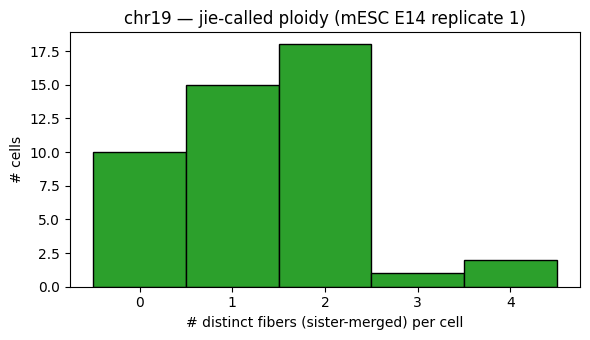

In [5]:
ploidy = cd.results['ploidy']
print('ploidy table:')
print(ploidy)
print('\nploidy distribution (n_sister_groups = distinct fibers):')
print(ploidy['n_sister_groups'].value_counts().sort_index())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(ploidy['n_sister_groups'], bins=np.arange(0, ploidy['n_sister_groups'].max() + 2) - 0.5,
        color='tab:green', edgecolor='black')
ax.set_xlabel('# distinct fibers (sister-merged) per cell')
ax.set_ylabel('# cells')
ax.set_title(f'{chr_to_use} — jie-called ploidy (mESC E14 replicate 1)')
plt.tight_layout()
plt.show()


mESC cells are nominally diploid; a peak at 2 is the expected
signature.  Deviations (triploid or more, or monoploid) reflect
aneuploidy or reconstruction noise.


## Agreement with the upstream labelID

The Takei 2021 dataset ships with a ``labelID`` column carrying an
upstream pre-assignment (0..3 plus -1 for rejected).  We can compare:
for each jie-called fiber, what fraction of its spots share the same
``labelID``?  A high purity means jie recovers the same fibers as the
upstream pipeline using only geometry + polymer physics.


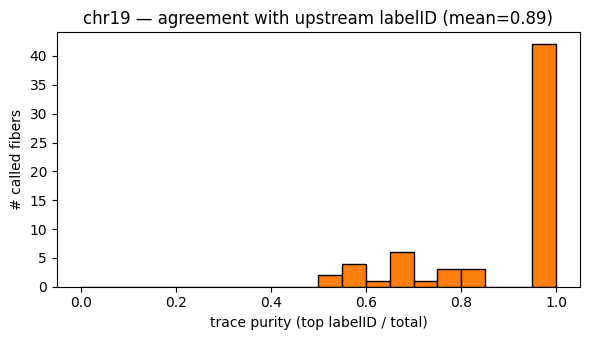

mean purity: 0.893
median: 1.000; 25th percentile: 0.768


In [6]:
# Join called trace_id back onto the original spots by spot_id
called = cd.spots[['spot_id', 'cell_id', 'trace_id']].copy()
called['trace_id'] = called['trace_id'].astype(int)
joined = sub.merge(called, on=['spot_id', 'cell_id'], how='inner')

purities = []
for (cell, tid), g in joined.groupby(['cell_id', 'trace_id']):
    top = g['labelID'].value_counts().iloc[0]
    purities.append(top / len(g))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(purities, bins=np.linspace(0, 1, 21), color='tab:orange', edgecolor='black')
ax.set_xlabel('trace purity (top labelID / total)')
ax.set_ylabel('# called fibers')
ax.set_title(f'{chr_to_use} — agreement with upstream labelID (mean={np.mean(purities):.2f})')
plt.tight_layout()
plt.show()
print(f'mean purity: {np.mean(purities):.3f}')
print(f'median: {np.median(purities):.3f}; 25th percentile: {np.quantile(purities, 0.25):.3f}')


## Feed jie output into FISHnet

Because ``align_spots`` returns a ``ChromData``, every downstream tool
in u-chrom works on the result unchanged.  We run FISHnet on the
jie-assigned traces to confirm the 3-D structure is domain-structured
and comparable with the FOF-CT-based analyses in tutorials 5 and 7.


In [7]:
from uchrom.strc.tad import call_domains_fishnet, FISHnetParams
from uchrom.fea import mean_distance_matrix

fishnet_df = call_domains_fishnet(
    cd, chrom=chr_to_use,
    params=FISHnetParams(
        plateau_size=3, n_louvain_runs=10, max_thresholds=30,
        min_coverage=0.3,
    ),
    verbose=True, max_traces=60,
)
print(f'{len(fishnet_df)} domains across {fishnet_df["trace_id"].nunique()} traces')


[fishnet/chr19] running on 60 traces × 60 bins; plateau_size=3, window=2


[fishnet/chr19] 25/60 traces


[fishnet/chr19] 50/60 traces


[fishnet/chr19] called domains in 57/60 traces; 229 domains total
229 domains across 57 traces


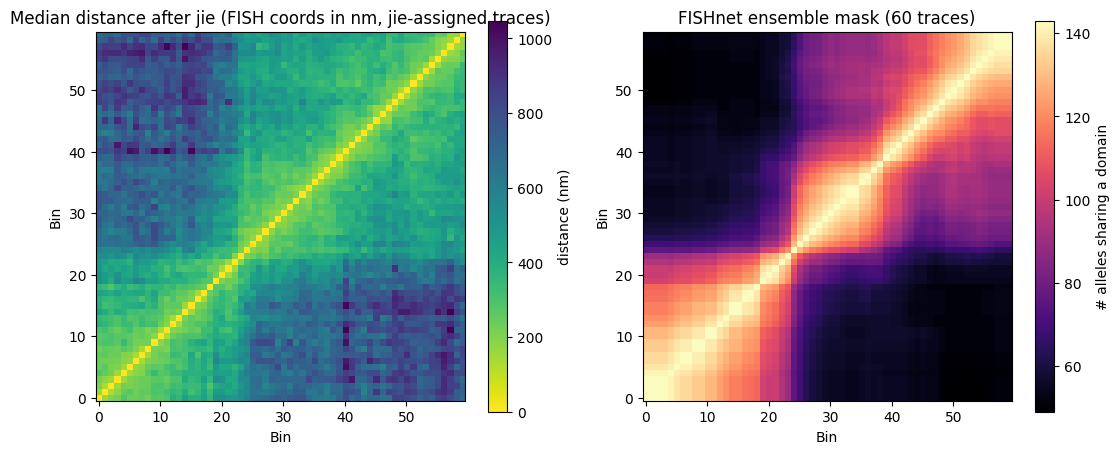

In [8]:
ens = cd.results['fishnet_ensemble']
dmat, _, _ = mean_distance_matrix(cd.get_chrom(chr_to_use).to_dataframe(), chrom=chr_to_use)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
im0 = axes[0].imshow(dmat, cmap='viridis_r', origin='lower')
axes[0].set_title('Median distance after jie (FISH coords in nm, jie-assigned traces)')
plt.colorbar(im0, ax=axes[0], label='distance (nm)')

im1 = axes[1].imshow(ens['mask'], cmap='magma', origin='lower')
axes[1].set_title(f'FISHnet ensemble mask ({ens["n_traces"]} traces)')
plt.colorbar(im1, ax=axes[1], label='# alleles sharing a domain')
for ax in axes: ax.set_xlabel('Bin'); ax.set_ylabel('Bin')
plt.tight_layout()
plt.show()


## Notes

- **Two parallel paths in ``uchrom``**: you can either start from an
  already-traced FOF-CT file (tutorials 2, 5, 6, 7 use 4DN
  `4DNFIHF3JCBY`) **or** from raw detections + jie (this tutorial).
  Both produce a `ChromData` with the same schema.
- **jie is SV-blind** — inversions/translocations break the DAG
  monotonicity assumption.  Flag or exclude known SV regions if
  working with tumour / abnormal samples.
- **Sister chromatid resolution is soft**: when sisters are very close
  (< ~150 nm) the aligner tends to merge them into one fiber.  This
  mirrors the upstream implementation's limits.
- For the full ~920 (cell, chromosome) combinations in this dataset,
  expect ~15 minutes on a single core.  Trivially parallelisable per
  (cell, chromosome) using ``multiprocessing``.
